# Lab 06 — Explaining Black-Box Models with LIME (Tabular, Text, Image)

**LIME** (*Local Interpretable Model-agnostic Explanations*, Ribeiro et al., 2016) explains **one prediction at a time**: it perturbs the input, watches how the black-box model's output changes, and fits a small weighted **linear model** around that one point. The linear model's coefficients are the explanation.

| Question | Data | Model | Explainer |
|---|---|---|---|
| Q1 Tabular | Breast Cancer Wisconsin (sklearn) | Random Forest | `LimeTabularExplainer` |
| Q2 Text | IMDb movie reviews (50k) | TF-IDF + Logistic Regression (vs Naive Bayes) | `LimeTextExplainer` |
| Q3 Image | One photo of a dog | MobileNetV2 (ImageNet, pretrained) | `LimeImageExplainer` |

**Extra learning components** (marked ★):
- ★ Q1: explanation **stability** vs number of samples, **local vs global** importance (impurity, permutation, aggregated LIME), and a **faithfulness / deletion test**.
- ★ Q2: Logistic Regression vs Naive Bayes, the model's **global** word weights, a **leave-one-word-out** check of LIME's ranking, and explaining a **misclassified** review.
- ★ Q3: superpixel **weight heatmap**, explanation of the **2nd-ranked class**, **three segmentation algorithms** compared, and a **deletion curve** (LIME regions vs random regions).

In [1]:
import os, re, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # silence TensorFlow C++ logs
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
POS, NEG = "#2e7d32", "#c62828"   # green = supports, red = opposes (used in every plot)

import sklearn, lime, tensorflow as tf
print("sklearn", sklearn.__version__, "| lime", getattr(lime, "__version__", "0.2.x"), "| tensorflow", tf.__version__)

I0000 00:00:1794808796.694532  105436 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


sklearn 1.9.1 | lime 0.2.x | tensorflow 2.21.0


I0000 00:00:1794808798.054887  105436 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


---
# Question 1 — LIME for Tabular Data (Breast Cancer Wisconsin)

## 1.1 Load the dataset
569 tumours, 30 numeric features computed from a digitised image of a fine-needle aspirate (radius, texture, concavity, ...; each as *mean*, *standard error* and *worst*). Target: `0 = malignant`, `1 = benign`.

In [2]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
X = pd.DataFrame(bc.data, columns=bc.feature_names)
y = pd.Series(bc.target, name="target")
class_names = [str(c) for c in bc.target_names]          # ['malignant', 'benign']

print("Shape:", X.shape)
print("Class counts:", dict(zip(class_names, np.bincount(y))))
X.iloc[:, :10].describe().T.round(2)

Shape: (569, 30)
Class counts: {'malignant': np.int64(212), 'benign': np.int64(357)}


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


## 1.2 Pre-processing and train/test split
- **Missing values / duplicates:** checked (there are none, but we verify rather than assume).
- **Scaling:** *not* applied. Random Forests split on thresholds, so they are scale-invariant, and LIME's tabular explainer computes its own statistics from the training data. Keeping raw units also makes the explanation readable (`worst area > 1084` is meaningful; `worst area > 0.87σ` is not).
- **Split:** 80/20, **stratified** so both sets keep the 37/63 malignant/benign ratio.

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score

print("Missing values:", int(X.isna().sum().sum()), "| duplicate rows:", int(X.duplicated().sum()))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Malignant share  train %.3f | test %.3f" % ((y_train == 0).mean(), (y_test == 0).mean()))

Missing values: 0 | duplicate rows: 0
Train: (455, 30) Test: (114, 30)
Malignant share  train 0.374 | test 0.368


## 1.3 Train a Random Forest

In [4]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
cv = cross_val_score(rf, X_train, y_train, cv=5, scoring="accuracy")
print("5-fold CV accuracy on train: %.4f ± %.4f" % (cv.mean(), cv.std()))
rf.fit(X_train, y_train)

5-fold CV accuracy on train: 0.9582 ± 0.0224


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

## 1.4 Evaluate: accuracy, precision, recall, confusion matrix
In a cancer screen the costly mistake is calling a malignant tumour benign, so precision and recall are reported **with malignant as the positive class** (`pos_label=0`), alongside the full per-class report.

In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

y_pred = rf.predict(X_test)
p_malig = rf.predict_proba(X_test)[:, 0]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (malignant)": precision_score(y_test, y_pred, pos_label=0),
    "Recall (malignant)": recall_score(y_test, y_pred, pos_label=0),
    "F1 (malignant)": f1_score(y_test, y_pred, pos_label=0),
    "ROC-AUC": roc_auc_score(y_test == 0, p_malig),
}
display(pd.Series(metrics, name="value").round(4).to_frame())
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

,value
Accuracy,0.9474
Precision (malignant),0.9286
Recall (malignant),0.9286
F1 (malignant),0.9286
ROC-AUC,0.9937


              precision    recall  f1-score   support

   malignant     0.9286    0.9286    0.9286        42
      benign     0.9583    0.9583    0.9583        72

    accuracy                         0.9474       114
   macro avg     0.9435    0.9435    0.9435       114
weighted avg     0.9474    0.9474    0.9474       114



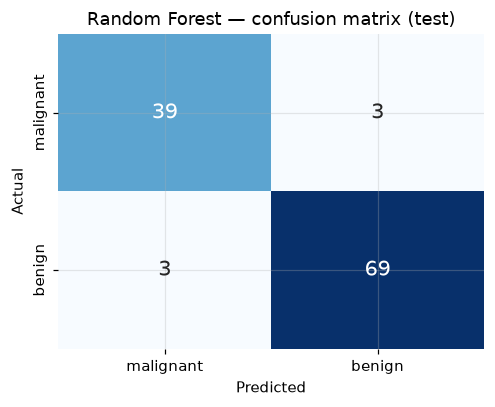

In [6]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=ax, annot_kws={"size": 14})
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Random Forest — confusion matrix (test)")
plt.tight_layout(); plt.show()

## 1.5 Explain one test prediction with `LimeTabularExplainer`
How LIME does it for tables:
1. **Discretize** each feature into quartiles of the *training* data (`discretize_continuous=True`) so the explanation reads as rules like `worst radius > 18.8`.
2. Generate `num_samples` **perturbed rows** around the instance by sampling each feature from the training distribution.
3. Ask the Random Forest for probabilities on all of them.
4. Weight each perturbed row by its **closeness** to the instance (exponential kernel) and fit a weighted **ridge regression**. Its coefficients are the feature contributions.

We explain a **malignant** test case (the class that matters clinically). The explanation is for the *predicted* class, so a positive weight means *pushes towards malignant*.

In [7]:
from lime.lime_tabular import LimeTabularExplainer

feature_names = list(X.columns)
def rf_predict(a):
    # LIME passes numpy arrays; wrap them so the forest sees the column names it was trained with
    return rf.predict_proba(pd.DataFrame(a, columns=feature_names))

tab_explainer = LimeTabularExplainer(
    X_train.values, feature_names=feature_names, class_names=class_names,
    mode="classification", discretize_continuous=True, random_state=SEED)

idx = int(np.where((y_pred == 0) & (y_test.values == 0))[0][0])   # first correctly-predicted malignant case
x0 = X_test.iloc[idx].values
proba0 = rf_predict(x0[None])[0]
label0 = int(proba0.argmax())
print(f"Test row {idx} | actual: {class_names[y_test.iloc[idx]]} | predicted: {class_names[label0]}")
print("RF probabilities:", dict(zip(class_names, proba0.round(3))))

exp_tab = tab_explainer.explain_instance(x0, rf_predict, labels=(label0,), num_features=10, num_samples=5000)
print(f"LIME local model: intercept={exp_tab.intercept[label0]:.3f}, "
      f"local prediction={exp_tab.local_pred[0]:.3f}, R²={exp_tab.score:.3f}")

Test row 0 | actual: malignant | predicted: malignant
RF probabilities: {'malignant': np.float64(1.0), 'benign': np.float64(0.0)}


LIME local model: intercept=0.239, local prediction=0.987, R²=0.654


### Plot 1 — feature importance bar chart (|weight|)
Magnitude only: *how much* each rule matters to this one prediction, regardless of direction.

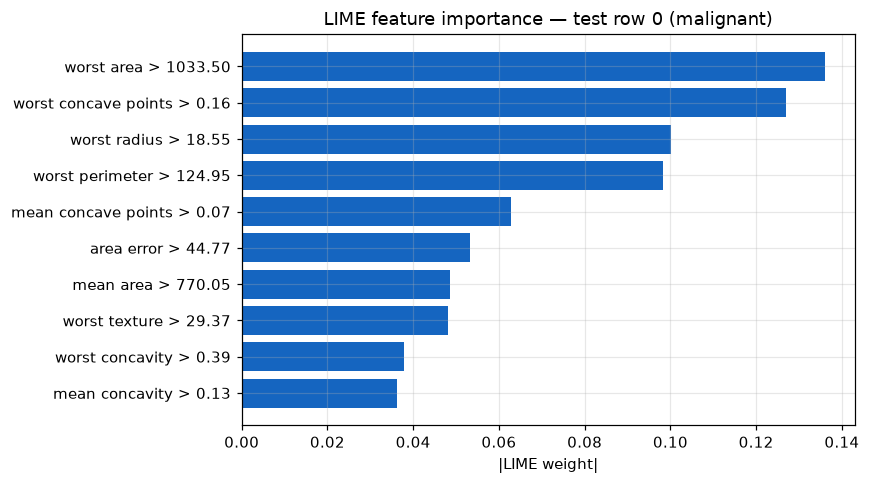

In [8]:
tab_list = exp_tab.as_list(label=label0)
imp = pd.DataFrame(tab_list, columns=["rule", "weight"])
imp["abs"] = imp.weight.abs()
imp = imp.sort_values("abs")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.rule, imp["abs"], color="#1565c0")
ax.set_xlabel("|LIME weight|"); ax.set_title(f"LIME feature importance — test row {idx} ({class_names[label0]})")
plt.tight_layout(); plt.show()

### Plot 2 — positive vs negative contributions
Green bars push the prediction **towards malignant**, red bars push it **towards benign**. (Same numbers as LIME's built-in `as_pyplot_figure`, drawn with consistent colours.)

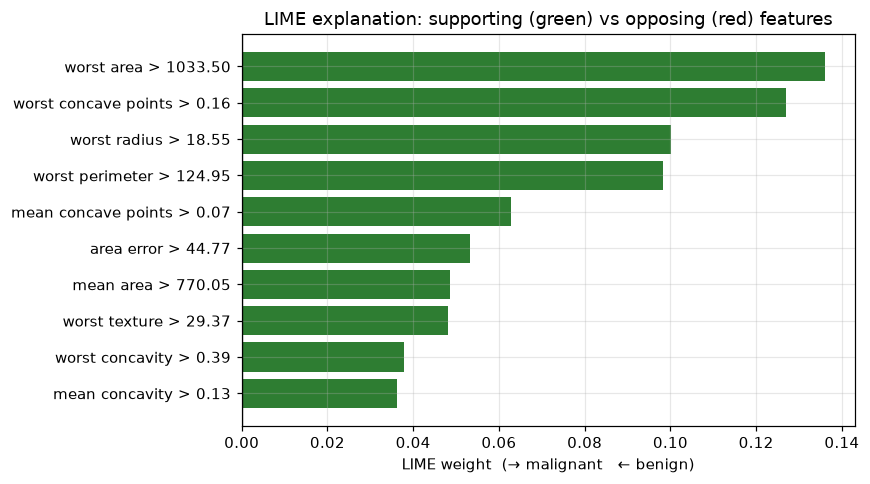

In [9]:
contrib = pd.DataFrame(tab_list, columns=["rule", "weight"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(contrib.rule, contrib.weight, color=[POS if w > 0 else NEG for w in contrib.weight])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel(f"LIME weight  (→ {class_names[label0]}   ← {class_names[1 - label0]})")
ax.set_title("LIME explanation: supporting (green) vs opposing (red) features")
plt.tight_layout(); plt.show()

## 1.6 The five most influential features
`as_map()` gives `(feature index, weight)` pairs, so we can line each rule up with the patient's actual value.

In [10]:
top5_idx = [f for f, w in exp_tab.as_map()[label0][:5]]
top5 = pd.DataFrame({
    "feature": [feature_names[f] for f in top5_idx],
    "rule": [r for r, w in tab_list[:5]],
    "instance value": [x0[f] for f in top5_idx],
    "train median": [X_train.iloc[:, f].median() for f in top5_idx],
    "LIME weight": [w for r, w in tab_list[:5]],
})
top5["effect"] = np.where(top5["LIME weight"] > 0, f"→ {class_names[label0]}", f"→ {class_names[1 - label0]}")
display(top5.round(4))

,feature,rule,instance value,train median,LIME weight,effect
0,worst area,worst area > 1033.50,1926.0000,683.4000,0.1361,→ malignant
1,worst concave points,worst concave points > 0.16,0.1941,0.0972,0.1270,→ malignant
2,worst radius,worst radius > 18.55,25.0500,14.9100,0.1002,→ malignant
3,worst perimeter,worst perimeter > 124.95,178.6000,97.5900,0.0982,→ malignant
4,mean concave points,mean concave points > 0.07,0.1144,0.0326,0.0627,→ malignant


**Reading it:** the top rules are all "size/shape is in the top quartile" (worst area / radius / perimeter / concave points). Those are exactly what a pathologist looks for: large, irregular nuclei with deep concavities. The model is right *for sensible reasons* on this case, which is the main thing LIME lets us check.

---
## ★ 1.7 Extra — how stable is a LIME explanation?
LIME is **random**: each run draws new perturbations. If two runs give different top-5 features, the explanation is not trustworthy. We repeat the explanation 10 times at three sample sizes and measure
- **Jaccard overlap** of the top-5 feature sets between runs (1 = identical), and
- the **spread** of each feature's weight.

In [11]:
from itertools import combinations

def top_k_set(exp, k=5):
    return {f for f, w in exp.as_map()[label0][:k]}

rows = []
for n in [500, 1000, 5000]:
    sets, t = [], time.time()
    for s in range(10):
        e = LimeTabularExplainer(X_train.values, feature_names=feature_names, class_names=class_names,
                                 discretize_continuous=True, random_state=s
                                 ).explain_instance(x0, rf_predict, labels=(label0,), num_features=5, num_samples=n)
        sets.append(top_k_set(e))
    jacc = [len(a & b) / len(a | b) for a, b in combinations(sets, 2)]
    rows.append({"num_samples": n, "mean Jaccard top-5": np.mean(jacc), "min Jaccard": np.min(jacc),
                 "sec per explanation": (time.time() - t) / 10})
stab = pd.DataFrame(rows)
display(stab.round(3))
assert stab["mean Jaccard top-5"].between(0, 1).all()

,num_samples,mean Jaccard top-5,min Jaccard,sec per explanation
0,500,0.748,0.667,0.445
1,1000,0.844,0.667,0.463
2,5000,0.822,0.667,0.553


500 samples is clearly less stable; from about 1,000 samples on, stability levels off and the cost grows linearly with the number of model calls. The minimum overlap stays at 4 of 5 features because the size features (radius / perimeter / area) are almost interchangeable and swap places between runs. For important decisions, use thousands of samples and report how stable the top features are.

## ★ 1.8 Extra — local vs global importance
LIME is **local** (one patient). Global methods describe the whole model:
- **Impurity importance** — built into the forest; fast but biased towards high-cardinality features.
- **Permutation importance** — accuracy drop when a column is shuffled on the test set; model-agnostic.
- **Aggregated LIME** — mean |weight| over 40 test explanations (a cheap version of SP-LIME).

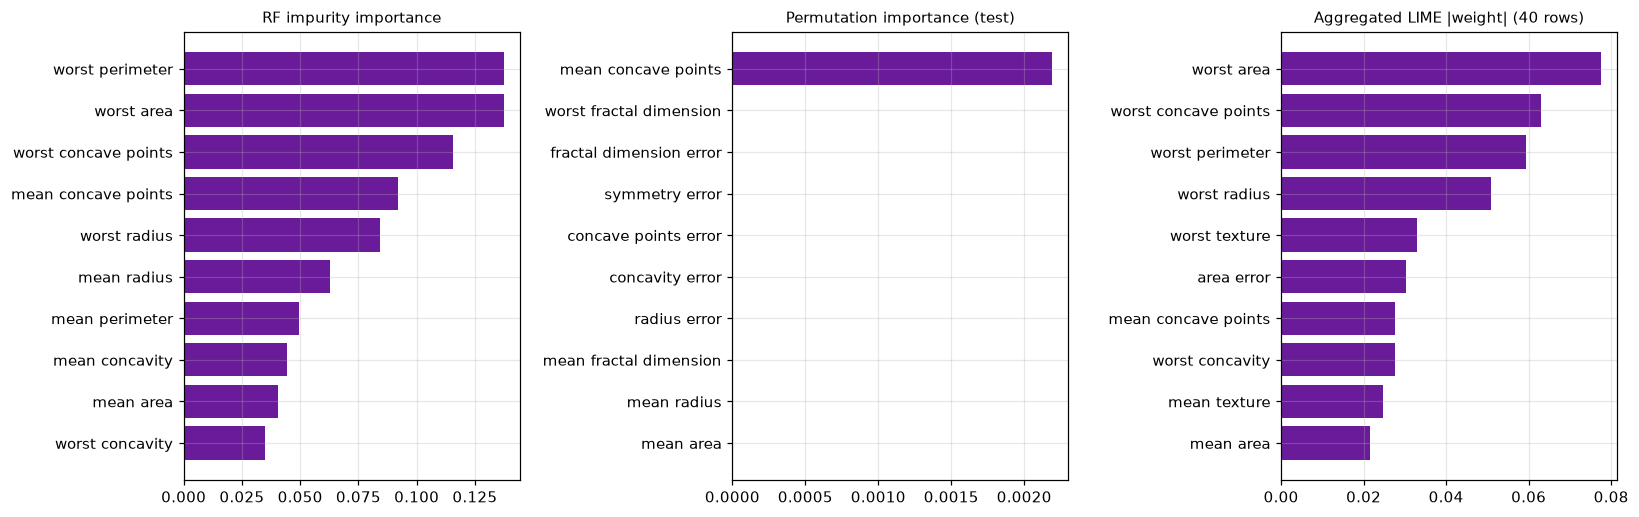

Spearman rank correlation between the three importance measures:


,impurity,permutation,agg_LIME
impurity,1.000,-0.302,0.866
permutation,-0.302,1.000,-0.350
agg_LIME,0.866,-0.350,1.000


In [12]:
from sklearn.inspection import permutation_importance

imp_rf = pd.Series(rf.feature_importances_, index=feature_names)
perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=SEED, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=feature_names)

agg = pd.Series(0.0, index=feature_names)
sample_rows = np.random.RandomState(SEED).choice(len(X_test), 40, replace=False)
for r in sample_rows:
    e = tab_explainer.explain_instance(X_test.values[r], rf_predict, labels=(0,), num_features=30, num_samples=1000)
    for f, w in e.as_map()[0]:
        agg.iloc[f] += abs(w) / len(sample_rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (name, s) in zip(axes, [("RF impurity importance", imp_rf),
                                ("Permutation importance (test)", imp_perm),
                                ("Aggregated LIME |weight| (40 rows)", agg)]):
    top = s.sort_values().tail(10)
    ax.barh(top.index, top.values, color="#6a1b9a")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

ranks = pd.DataFrame({"impurity": imp_rf, "permutation": imp_perm, "agg_LIME": agg}).rank(ascending=False)
print("Spearman rank correlation between the three importance measures:")
display(ranks.corr(method="spearman").round(3))

Impurity importance and aggregated LIME tend to agree on the "size" features (worst area / radius / perimeter / concave points). Permutation importance is lower and noisier for each one individually because those features are **strongly correlated**: shuffle one and the forest uses its twin, so no single column looks essential. Keep this in mind for LIME too, since it perturbs features independently and so also builds unrealistic rows (e.g. huge radius with tiny area).

## ★ 1.9 Extra — is the explanation faithful? (deletion test)
If LIME's top features really drive the prediction, **removing** them (replacing with the training median) should drop `P(malignant)` faster than removing random features.

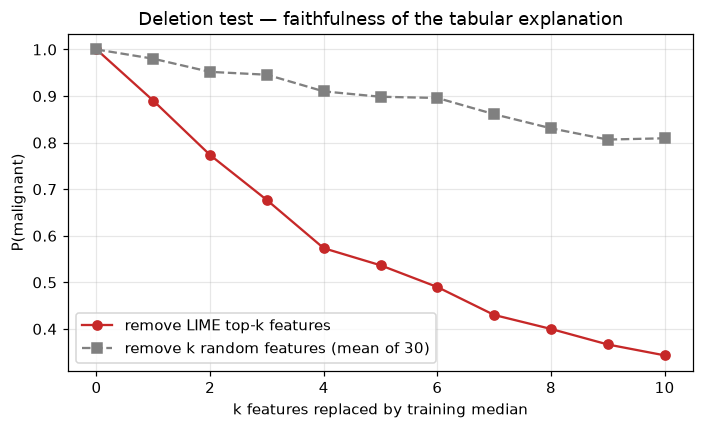

P(malignant) after removing LIME top-5: 0.537 vs random-5: 0.898


In [13]:
order = [f for f, w in exp_tab.as_map()[label0]]           # LIME ranking (top-10)
medians = X_train.median().values
rng = np.random.RandomState(SEED)

def p_after_removing(feats):
    x = x0.copy(); x[list(feats)] = medians[list(feats)]
    return rf_predict(x[None])[0, label0]

ks = range(0, 11)
lime_curve = [p_after_removing(order[:k]) for k in ks]
rand_curve = [np.mean([p_after_removing(rng.choice(30, k, replace=False)) for _ in range(30)]) for k in ks]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(ks, lime_curve, "o-", color=NEG, label="remove LIME top-k features")
ax.plot(ks, rand_curve, "s--", color="gray", label="remove k random features (mean of 30)")
ax.set_xlabel("k features replaced by training median"); ax.set_ylabel(f"P({class_names[label0]})")
ax.set_title("Deletion test — faithfulness of the tabular explanation"); ax.legend()
plt.tight_layout(); plt.show()
print("P(malignant) after removing LIME top-5: %.3f vs random-5: %.3f" % (lime_curve[5], rand_curve[5]))

---
# Question 2 — LIME for Text Data (IMDb sentiment)

## 2.1 Load IMDb
`keras.datasets.imdb` ships 50,000 labelled reviews (25k train + 25k test, balanced). They are stored as word-index sequences, so we **decode them back to text** with the word index (indices are offset by 3 for the reserved padding/start/unknown tokens). The decoded text is lower-case with punctuation removed, but still contains HTML line-break debris (`br br`) that we clean below.

In [14]:
from tensorflow.keras.datasets import imdb

(xa, ya), (xb, yb) = imdb.load_data()
word_index = imdb.get_word_index()
inv_index = {i + 3: w for w, i in word_index.items()}

def decode(seq):
    return " ".join(inv_index.get(i, "") for i in seq[1:])   # seq[0] is the <start> token

reviews = pd.DataFrame({"review": [decode(s) for s in np.concatenate([xa, xb])],
                        "label": np.concatenate([ya, yb])})
print(reviews.shape, "| positive share: %.3f" % reviews.label.mean())
print(reviews.review[0][:400], "...")

(50000, 2) | positive share: 0.500
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert redford's is an amazing actor and now the same being director norman's father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it  ...


## 2.2 Pre-process text and handle missing values
1. Treat empty / whitespace-only reviews as missing and drop them; drop exact **duplicates** (IMDb has a few hundred, and they would leak across a split).
2. `clean_text`: lower-case, strip HTML break tags and their `br` debris, keep only letters and apostrophes (so `don't` survives), collapse whitespace.
3. We do **not** remove stop words: sklearn's English list contains `not`, `no`, `nor`, which flip sentiment.

In [15]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>|\bbr\b", " ", text)       # HTML line breaks
    text = re.sub(r"[^a-z' ]+", " ", text)              # unnecessary symbols / digits
    text = re.sub(r"\s+", " ", text).strip()
    return text

assert clean_text("Great<br /><br />film!! 10/10 br br don't") == "great film don't"

reviews["review"] = reviews.review.replace(r"^\s*$", np.nan, regex=True)
print("Missing reviews:", int(reviews.review.isna().sum()))
reviews = reviews.dropna(subset=["review"])
reviews["clean"] = reviews.review.map(clean_text)
before = len(reviews)
reviews = reviews.drop_duplicates(subset="clean").reset_index(drop=True)
print(f"Dropped {before - len(reviews)} duplicate reviews -> {len(reviews)} remain")
reviews["n_words"] = reviews.clean.str.split().str.len()
print("Words per review: median %d, 95th pct %d" % (reviews.n_words.median(), reviews.n_words.quantile(.95)))

Missing reviews: 0


Dropped 423 duplicate reviews -> 49577 remain


Words per review: median 172, 95th pct 584


## 2.3 TF-IDF features and 2.4 classifier
- `TfidfVectorizer`: **unigrams + bigrams** (bigrams catch `not good`, `waste of`), `min_df=3` drops typos, `max_df=0.9` drops near-universal words, `sublinear_tf` dampens repeated words, vocabulary capped at 100k.
- The vectorizer and classifier live in **one `Pipeline`**, so LIME can pass raw strings straight in (`pipe.predict_proba(list_of_texts)`), and the vectorizer is fitted on training text only.
- Main model: **Logistic Regression**; ★ we also train **Multinomial Naive Bayes** for comparison.

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

txt_train, txt_test, s_train, s_test = train_test_split(
    reviews.clean, reviews.label, test_size=0.2, stratify=reviews.label, random_state=SEED)

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, max_features=100_000)

models = {"Logistic Regression": make_pipeline(tfidf(), LogisticRegression(C=4, max_iter=2000)),
          "Multinomial NB": make_pipeline(tfidf(), MultinomialNB(alpha=0.3))}
for name, m in models.items():
    t = time.time(); m.fit(txt_train, s_train)
    print(f"{name:20s} trained in {time.time() - t:5.1f}s")
pipe = models["Logistic Regression"]
print("Vocabulary size:", len(pipe[0].vocabulary_))

Logistic Regression  trained in  20.3s


Multinomial NB       trained in  16.7s
Vocabulary size: 100000


## 2.5 Evaluate: accuracy and classification report

In [17]:
sent_names = ["negative", "positive"]
for name, m in models.items():
    pred = m.predict(txt_test)
    print(f"=== {name}: accuracy {accuracy_score(s_test, pred):.4f}")
    print(classification_report(s_test, pred, target_names=sent_names, digits=4))

=== Logistic Regression: accuracy 0.9136
              precision    recall  f1-score   support

    negative     0.9213    0.9036    0.9124      4939
    positive     0.9062    0.9234    0.9147      4977

    accuracy                         0.9136      9916
   macro avg     0.9137    0.9135    0.9136      9916
weighted avg     0.9137    0.9136    0.9136      9916



=== Multinomial NB: accuracy 0.8844
              precision    recall  f1-score   support

    negative     0.8843    0.8836    0.8839      4939
    positive     0.8846    0.8853    0.8849      4977

    accuracy                         0.8844      9916
   macro avg     0.8844    0.8844    0.8844      9916
weighted avg     0.8844    0.8844    0.8844      9916



## 2.6 Explain one review with `LimeTextExplainer`
For text, LIME's "features" are the **distinct words** of the review. Each perturbed sample is the review with a random subset of words **deleted**; the pipeline scores each one, and a weighted linear model learns how much each word's presence moves `P(positive)`.

We choose a test review of 60–160 words that the model gets right with moderate confidence (0.75–0.92), so it is short enough to read and editing it can plausibly change the result.

In [18]:
from lime.lime_text import LimeTextExplainer

p_test = pipe.predict_proba(txt_test)[:, 1]
cand = pd.DataFrame({"text": txt_test.values, "y": s_test.values, "p": p_test})
cand["n"] = cand.text.str.split().str.len()
cand["conf"] = np.maximum(cand.p, 1 - cand.p)
cand = cand[(cand.n.between(60, 160)) & (cand.conf.between(0.75, 0.92)) & ((cand.p > .5) == cand.y)]
review = cand.text.iloc[0]
true_lbl = int(cand.y.iloc[0])
p_orig = pipe.predict_proba([review])[0]
pred_lbl = int(p_orig.argmax())
print(f"Actual: {sent_names[true_lbl]} | predicted: {sent_names[pred_lbl]} | P = {p_orig.round(3)}\n")
print(review)

text_explainer = LimeTextExplainer(class_names=sent_names, random_state=SEED)
exp_txt = text_explainer.explain_instance(review, pipe.predict_proba, labels=(1,), num_features=12, num_samples=3000)
print(f"\nLIME local fit R² = {exp_txt.score:.3f}")

Actual: positive | predicted: positive | P = [0.137 0.863]

this film would be particularly fun for anyone who has been in the film industry especially in any indie capacity those whose inheritance includes a film introduction may not appreciate it quite as much i am hard to please in the documentary category this doc is different though its pleasure comes from an earthy realism of indie filmmaker punks who are a hoot to be around and watch whether you've ever wondered what it is like to be in films in front of or behind the camera or whether you have worked your way through the sometimes painful and hard but rewarding indie world you'll certainly get a kick out of this film



LIME local fit R² = 0.579


### Plot 1 — word importance bar chart
Weights are for the **positive** class: green words push towards *positive*, red towards *negative*.

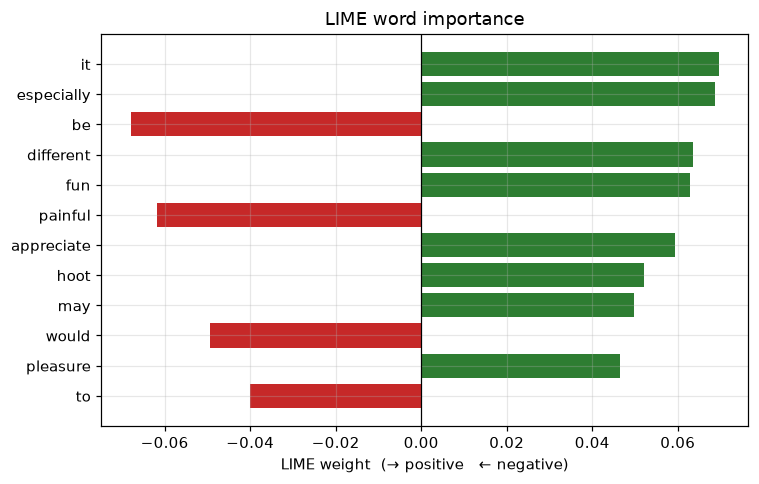

In [19]:
words = pd.DataFrame(exp_txt.as_list(label=1), columns=["word", "weight"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(words.word, words.weight, color=[POS if w > 0 else NEG for w in words.weight])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("LIME weight  (→ positive   ← negative)"); ax.set_title("LIME word importance")
plt.tight_layout(); plt.show()

### Plot 2 — highlighted text
Each explained word is shaded green (supports positive) or red (supports negative), with opacity proportional to |weight|.

In [20]:
def highlight(text, weights):
    wmax = max(abs(w) for w in weights.values())
    out = []
    for tok in text.split():
        w = weights.get(tok)
        if w is None:
            out.append(tok)
        else:
            rgb = "46,125,50" if w > 0 else "198,40,40"
            out.append(f'<span style="background:rgba({rgb},{0.15 + 0.75 * abs(w) / wmax:.2f});'
                       f'padding:1px 3px;border-radius:3px" title="{w:+.3f}">{tok}</span>')
    return ('<div style="line-height:2;font-family:sans-serif;font-size:14px;max-width:900px">'
            '<b style="color:#2e7d32">green = positive</b> · <b style="color:#c62828">red = negative</b><br>'
            + " ".join(out) + "</div>")

word_w = dict(exp_txt.as_list(label=1))
display(HTML(highlight(review, word_w)))

## 2.7 Modify / remove the two most influential words
We take the two words that most strongly support the **predicted** class and
- **(a) remove** them everywhere in the review, and
- **(b) replace** them with the model's single strongest word of the *opposite* sentiment (read from the LR coefficients).

Then we re-score every version.

In [21]:
sign = 1 if pred_lbl == 1 else -1                     # weights are w.r.t. "positive"
support = sorted(word_w.items(), key=lambda kv: -sign * kv[1])[:2]
support = [(str(w), round(float(v), 4)) for w, v in support]
top2 = [w for w, _ in support]
print("Two most influential words supporting the prediction:", support)

vocab = pipe[0].get_feature_names_out()
coefs = pipe[-1].coef_[0]
unigram = np.array([" " not in v for v in vocab])
opposite = str(vocab[unigram][np.argmin(sign * coefs[unigram])])
print("Strongest opposite-sentiment word in the model:", repr(opposite))

def sub_words(text, targets, repl):
    for t in targets:
        text = re.sub(rf"\b{re.escape(t)}\b", repl, text)
    return re.sub(r"\s+", " ", text).strip()

variants = {
    "original": review,
    f"removed {top2}": sub_words(review, top2, ""),
    f"replaced with '{opposite}'": sub_words(review, top2, opposite),
}
probs = pd.DataFrame({k: pipe.predict_proba([v])[0] for k, v in variants.items()}, index=sent_names).T
probs["predicted"] = probs.idxmax(axis=1)
display(probs.round(4))

Two most influential words supporting the prediction: [('it', 0.0695), ('especially', 0.0687)]


Strongest opposite-sentiment word in the model: 'worst'


,negative,positive,predicted
original,0.1367,0.8633,positive
"removed ['it', 'especially']",0.2666,0.7334,positive
replaced with 'worst',0.5910,0.4090,negative


### Plot 3 — predicted class probabilities compared
Left: every edited version under Logistic Regression. Right: ★ the original review under both classifiers.

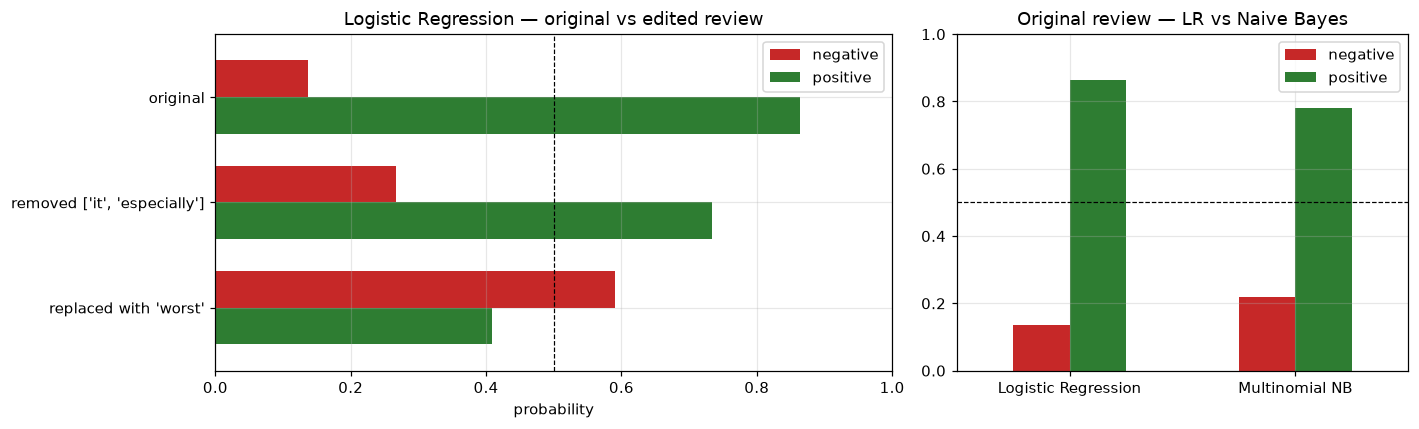

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 2]})
probs[sent_names].plot.barh(ax=axes[0], color=[NEG, POS], width=0.7)
axes[0].axvline(0.5, ls="--", color="k", lw=0.8)
axes[0].set_xlim(0, 1); axes[0].set_xlabel("probability"); axes[0].set_title("Logistic Regression — original vs edited review")
axes[0].invert_yaxis()

cmp = pd.DataFrame({n: m.predict_proba([review])[0] for n, m in models.items()}, index=sent_names).T
cmp.plot.bar(ax=axes[1], color=[NEG, POS], rot=0)
axes[1].axhline(0.5, ls="--", color="k", lw=0.8)
axes[1].set_ylim(0, 1); axes[1].set_title("Original review — LR vs Naive Bayes")
plt.tight_layout(); plt.show()

## ★ 2.8 Extra — global view: the model's own word weights
For a linear model we can read the **global** explanation directly from the coefficients. LIME is still useful because it shows which of these words are *present in this review* and how much they matter *here*.

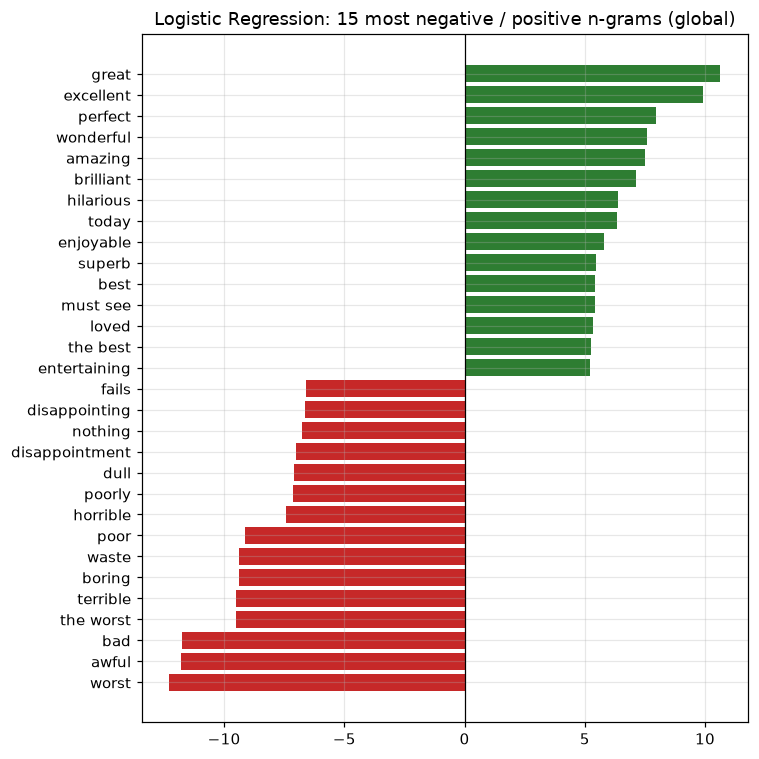

In [23]:
coef_s = pd.Series(coefs, index=vocab).sort_values()
glob = pd.concat([coef_s.head(15), coef_s.tail(15)])
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(glob.index, glob.values, color=[POS if v > 0 else NEG for v in glob.values])
ax.axvline(0, color="k", lw=0.8); ax.set_title("Logistic Regression: 15 most negative / positive n-grams (global)")
plt.tight_layout(); plt.show()

## ★ 2.9 Extra — does LIME rank the words correctly? (leave-one-word-out)
A cheap ground truth: delete **one** word at a time (all of its occurrences) and measure the exact change in `P(positive)`. If LIME is faithful, its weights should correlate strongly with these drops.

In [24]:
from scipy.stats import spearmanr

base = p_orig[1]
loo = {w: base - pipe.predict_proba([sub_words(review, [w], "")])[0, 1] for w in word_w}
chk = pd.DataFrame({"LIME weight": word_w, "leave-one-out ΔP(pos)": loo}).sort_values("LIME weight")
rho = spearmanr(chk["LIME weight"], chk["leave-one-out ΔP(pos)"]).correlation
display(chk.round(4))
print(f"Spearman correlation LIME vs leave-one-out: {rho:.3f}")

,LIME weight,leave-one-out ΔP(pos)
be,-0.0679,-0.0476
painful,-0.0617,-0.0329
would,-0.0494,-0.0308
to,-0.0401,-0.0355
pleasure,0.0465,0.0221
may,0.0498,0.0429
hoot,0.0520,0.0308
appreciate,0.0594,0.0442
fun,0.0629,0.0394
different,0.0637,0.0395


Spearman correlation LIME vs leave-one-out: 0.846


## ★ 2.10 Extra — explaining a mistake
Explanations are most useful when the model is **wrong**. Here is the most confidently misclassified short test review.

In [25]:
wrong = pd.DataFrame({"text": txt_test.values, "y": s_test.values, "p": p_test})
wrong["n"] = wrong.text.str.split().str.len()
wrong = wrong[((wrong.p > .5) != wrong.y) & (wrong.n < 120)]
wrong["err"] = (wrong.p - wrong.y).abs()
bad = wrong.sort_values("err", ascending=False).iloc[0]
print(f"Actual: {sent_names[bad.y]} | predicted P(positive) = {bad.p:.3f}")
exp_bad = text_explainer.explain_instance(bad.text, pipe.predict_proba, labels=(1,), num_features=10, num_samples=3000)
display(HTML(highlight(bad.text, dict(exp_bad.as_list(label=1)))))

Actual: negative | predicted P(positive) = 0.971


Typical failure patterns revealed this way: **sarcasm**, a review that *describes* a bad plot or a "bad" character of an otherwise loved film, or a reviewer who praises the actors but rates the movie low. A bag-of-words model has no notion of *who* or *what* a word refers to.

---
# Question 3 — LIME for Image Data (MobileNetV2)

## 3.1 Load the pretrained model
**MobileNetV2** trained on ImageNet (1000 classes, 3.5M parameters). It is small and fast on CPU, which matters because LIME will call it about a thousand times.

In [26]:
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input, decode_predictions

tf.random.set_seed(SEED)
mnet = MobileNetV2(weights="imagenet")
print(f"MobileNetV2: {mnet.count_params():,} parameters, input {mnet.input_shape}")

MobileNetV2: 3,538,984 parameters, input (None, 224, 224, 3)


## 3.2 Select an image and 3.3 pre-process it
A photo of a yellow Labrador (from TensorFlow's tutorial images), saved to `data/`. Pre-processing for MobileNetV2:
1. resize to **224 × 224** RGB,
2. keep a copy in **[0, 1]** for LIME and plotting,
3. inside the classifier function: scale to 0–255 and call `preprocess_input`, which maps pixels to **[-1, 1]**, the range MobileNetV2 was trained on.

In [27]:
from tensorflow.keras.utils import get_file, load_img, img_to_array

IMG_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg"
img_path = get_file("labrador.jpg", IMG_URL, cache_dir=".", cache_subdir="data")
img = img_to_array(load_img(img_path, target_size=(224, 224))) / 255.0      # float in [0, 1]

def classify(batch01):
    # batch of [0,1] images -> softmax probabilities over 1000 ImageNet classes
    return mnet.predict(preprocess_input(np.asarray(batch01) * 255.0), verbose=0)

print("image array:", img.shape, img.dtype, f"range [{img.min():.2f}, {img.max():.2f}]")

image array: (224, 224, 3) float32 range [0.00, 1.00]


## 3.4 Predict — top-3 classes

1. Labrador_retriever        0.4692
2. Eskimo_dog                0.0537
3. Ibizan_hound              0.0244


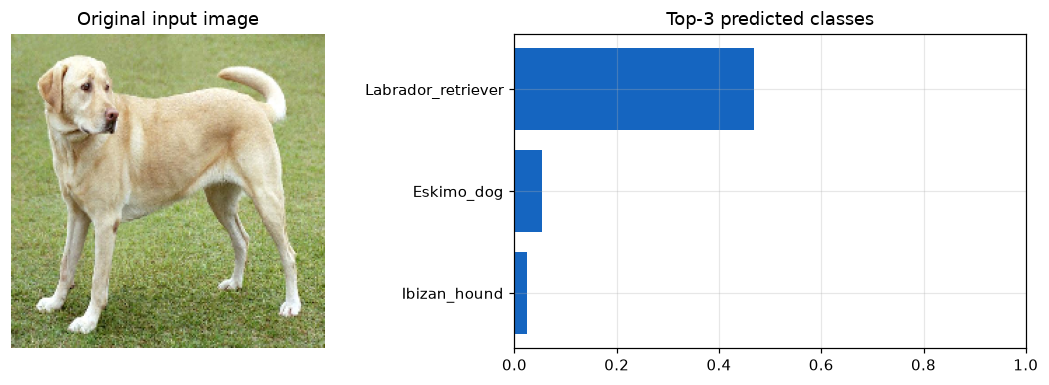

In [28]:
probs_img = classify(img[None])[0]
top3 = decode_predictions(probs_img[None], top=3)[0]
top3_ids = list(np.argsort(probs_img)[::-1][:3])
for rank, (wnid, name, p) in enumerate(top3, 1):
    print(f"{rank}. {name:25s} {p:.4f}")
pred_id = top3_ids[0]
pred_name = top3[0][1]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title("Original input image")
axes[1].barh([t[1] for t in top3][::-1], [t[2] for t in top3][::-1], color="#1565c0")
axes[1].set_xlim(0, 1); axes[1].set_title("Top-3 predicted classes")
plt.tight_layout(); plt.show()

## 3.5 Apply `LimeImageExplainer` and 3.6 superpixel segmentation
Pixels are too many and too small to be features, so LIME first groups them into **superpixels** (patches of similar colour). Each perturbed sample switches a random subset of superpixels **off** (painted black, `hide_color=0`); the model scores each sample; a weighted linear model learns how much each superpixel contributes to a class.

We use **Quickshift** (LIME's default; `kernel_size=4, max_dist=200, ratio=0.2`) and 1,000 samples.

In [29]:
from lime.lime_image import LimeImageExplainer
from lime.wrappers.scikit_image import SegmentationAlgorithm
from skimage.segmentation import mark_boundaries

quickshift = SegmentationAlgorithm("quickshift", kernel_size=4, max_dist=200, ratio=0.2, random_seed=SEED)
segments = quickshift(img)
print("Number of superpixels:", segments.max() + 1)

img_explainer = LimeImageExplainer(random_state=SEED)
t = time.time()
# labels reversed: LIME keeps only the R² of the last label fitted, so fit the predicted class last
exp_img = img_explainer.explain_instance(img, classify, labels=top3_ids[::-1], top_labels=None, hide_color=0,
                                         num_samples=1000, batch_size=50, segmentation_fn=quickshift,
                                         random_seed=SEED)
print(f"LIME image explanation took {time.time() - t:.1f}s | local R² for '{pred_name}': {exp_img.score:.3f}")

Number of superpixels: 33


  0%|          | 0/1000 [00:00<?, ?it/s]

LIME image explanation took 26.0s | local R² for 'Labrador_retriever': 0.459


## 3.7 Plots
### Original, superpixels, supporting regions, opposing regions
- **Supporting** = the 5 superpixels with the largest *positive* weight for the predicted class (everything else greyed out).
- **Opposing** = superpixels with *negative* weight, i.e. whose presence lowers the class probability (drawn in red if any exist).

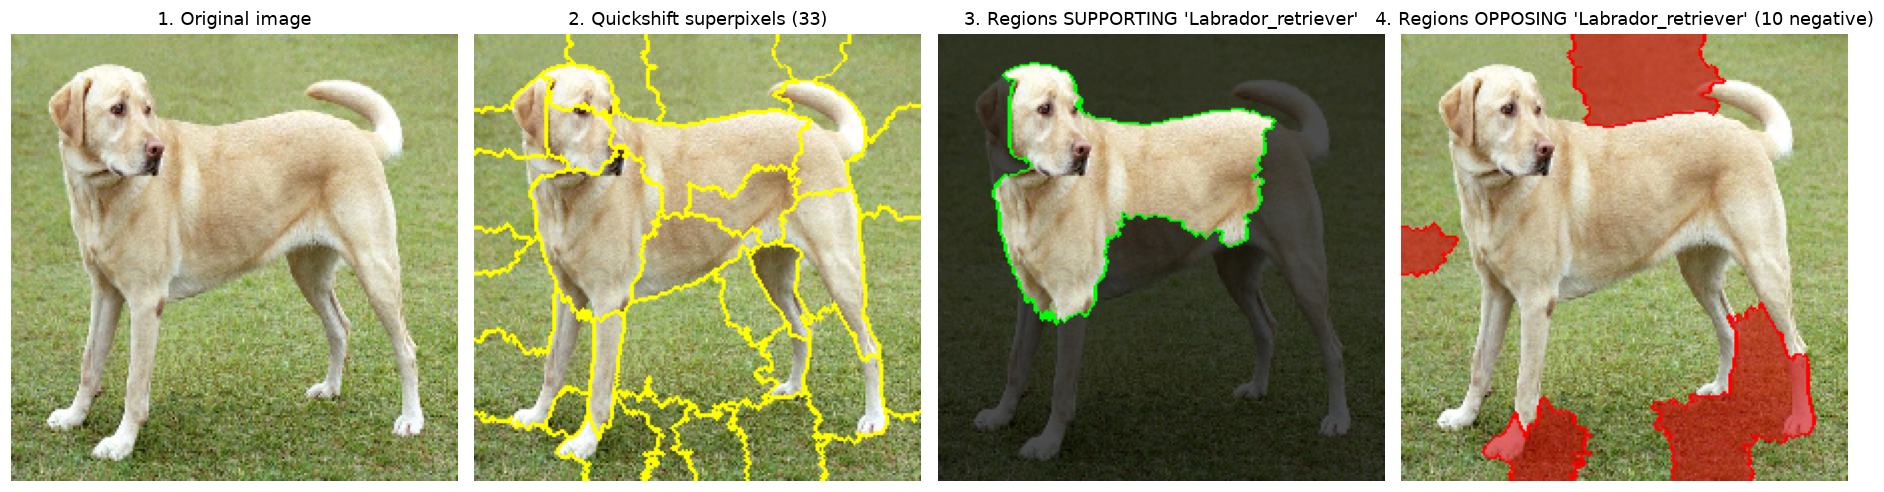

In [30]:
def regions(label, positive_only, negative_only=False, k=5, hide_rest=False):
    tmp, mask = exp_img.get_image_and_mask(label, positive_only=positive_only, negative_only=negative_only,
                                           num_features=k, hide_rest=hide_rest, min_weight=0.0)
    return tmp, mask

w_pred = dict(exp_img.local_exp[pred_id])
n_neg = sum(w < 0 for w in w_pred.values())

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
axes[0].imshow(img); axes[0].set_title("1. Original image")
axes[1].imshow(mark_boundaries(img, segments, color=(1, 1, 0))); axes[1].set_title(f"2. Quickshift superpixels ({segments.max() + 1})")

tmp, mask = regions(pred_id, positive_only=True, k=5, hide_rest=False)
shown = img * 0.3 + 0.7 * img * mask[..., None]          # dim everything outside the mask
axes[2].imshow(mark_boundaries(shown, mask, color=(0, 1, 0)))
axes[2].set_title(f"3. Regions SUPPORTING '{pred_name}'")

if n_neg:
    tmp, mask_n = regions(pred_id, positive_only=False, negative_only=True, k=5)
    over = img.copy(); over[mask_n == 1] = over[mask_n == 1] * 0.4 + np.array([0.8, 0, 0]) * 0.6
    axes[3].imshow(mark_boundaries(over, mask_n, color=(1, 0, 0)))
    axes[3].set_title(f"4. Regions OPPOSING '{pred_name}' ({n_neg} negative)")
else:
    axes[3].imshow(img); axes[3].set_title("4. No opposing regions found")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

### ★ Superpixel weight heatmap
Instead of a hard top-5 cut-off, colour **every** superpixel by its LIME weight (green = supports, red = opposes) to see the whole picture.

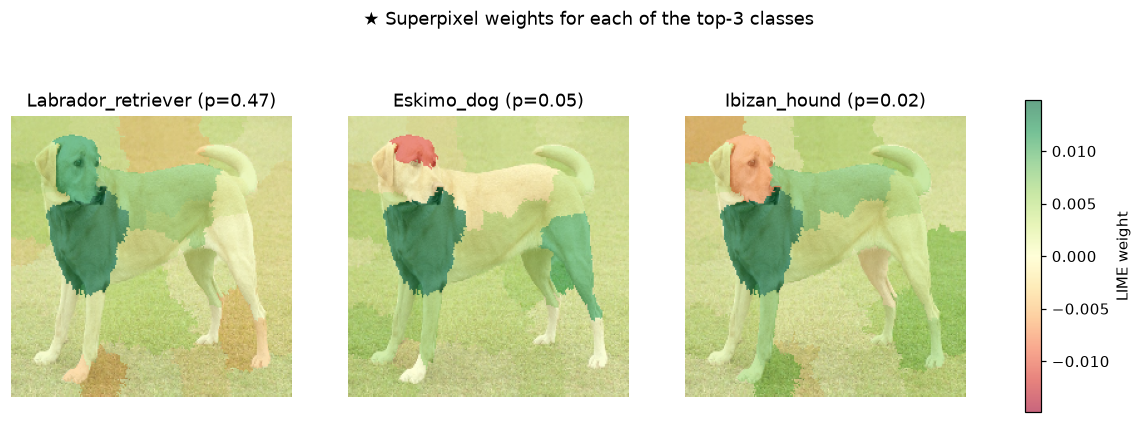

In [31]:
def weight_map(label):
    m = np.zeros(segments.shape)
    for seg, w in exp_img.local_exp[label]:
        m[segments == seg] = w
    return m

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, lid, (_, name, p) in zip(axes, top3_ids, top3):
    wm = weight_map(lid); lim = np.abs(wm).max()
    ax.imshow(img); im = ax.imshow(wm, cmap="RdYlGn", vmin=-lim, vmax=lim, alpha=0.6)
    ax.set_title(f"{name} (p={p:.2f})"); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="LIME weight")
plt.suptitle("★ Superpixel weights for each of the top-3 classes")
plt.show()

## 3.8 Mask important regions and watch the probability change
We black out the top-k **supporting** superpixels and re-predict. For comparison we also black out (a) k **random** superpixels and (b) the **opposing** superpixels (which should *raise* the probability).

,P(Labrador_retriever),new top-1
original,0.4692,Labrador_retriever
mask top-3 supporting,0.0098,Eskimo_dog
mask top-5 supporting,0.0036,borzoi
mask 5 random,0.0408,muzzle
mask opposing,0.9059,Labrador_retriever


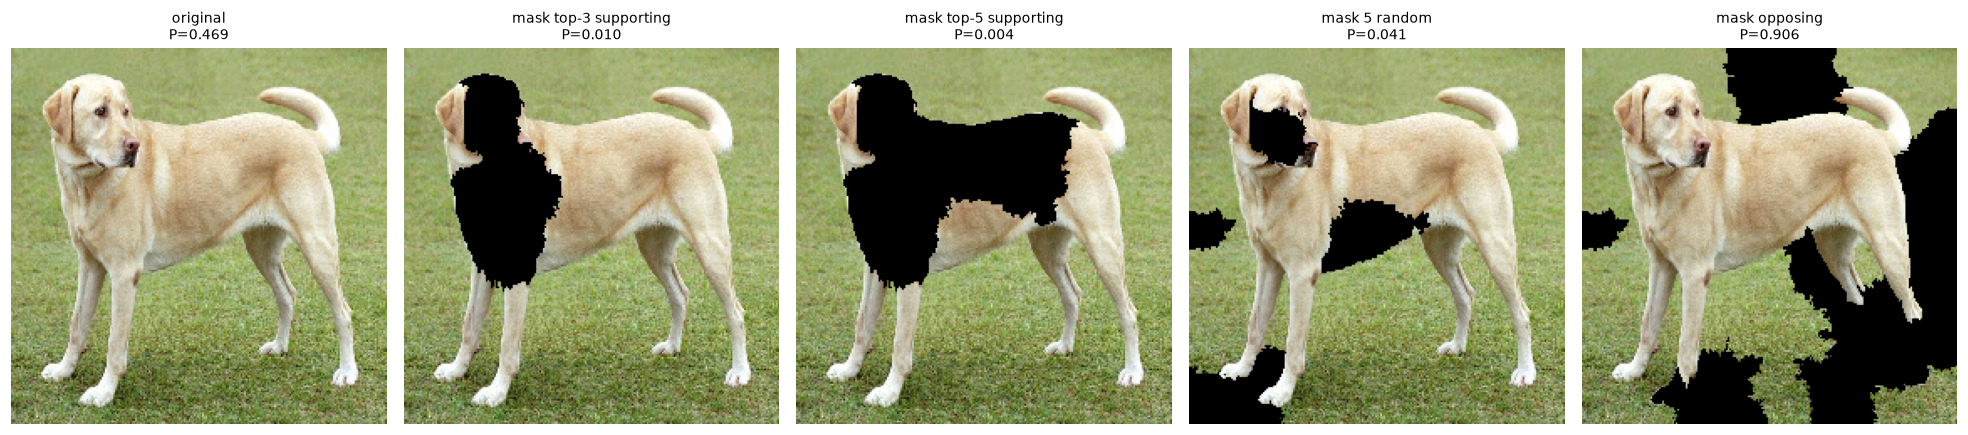

In [32]:
pos_segs = [s for s, w in exp_img.local_exp[pred_id] if w > 0]     # sorted by |weight| -> keep order
neg_segs = [s for s, w in exp_img.local_exp[pred_id] if w < 0]

def masked(segs):
    out = img.copy(); out[np.isin(segments, segs)] = 0
    return out

tests = {"original": img,
         "mask top-3 supporting": masked(pos_segs[:3]),
         "mask top-5 supporting": masked(pos_segs[:5]),
         "mask 5 random": masked(np.random.RandomState(SEED).choice(segments.max() + 1, 5, replace=False)),
         "mask opposing": masked(neg_segs) if neg_segs else img}
P = classify(np.stack(list(tests.values())))
res = pd.DataFrame({"P(" + pred_name + ")": P[:, pred_id],
                    "new top-1": [decode_predictions(p[None], top=1)[0][0][1] for p in P]}, index=tests.keys())
display(res.round(4))

fig, axes = plt.subplots(1, len(tests), figsize=(18, 3.8))
for ax, (name, im), p in zip(axes, tests.items(), P[:, pred_id]):
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{name}\nP={p:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

## ★ 3.9 Extra — deletion curve (faithfulness)
Remove superpixels one by one in LIME's order and track `P(predicted class)`; repeat with random orders. A faithful explanation makes the curve fall **fast**, so its area under the curve (AUC) is **small**.

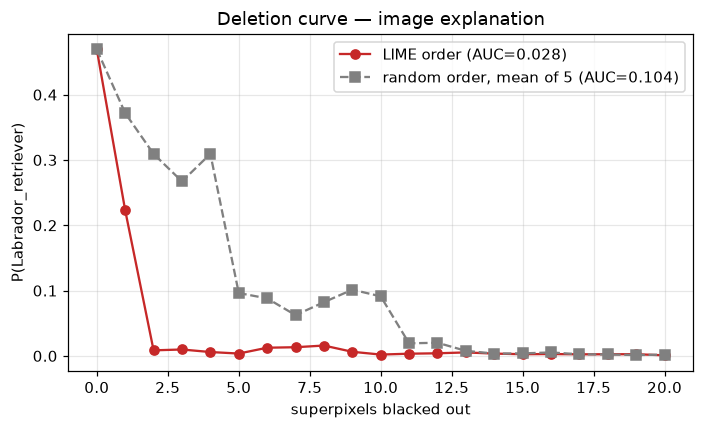

In [33]:
K = min(20, len(pos_segs))
lime_order = [s for s, w in exp_img.local_exp[pred_id]]
lime_curve = classify(np.stack([masked(lime_order[:k]) for k in range(K + 1)]))[:, pred_id]
rand_curves = []
rs = np.random.RandomState(SEED)
for _ in range(5):
    order_r = rs.permutation(segments.max() + 1)
    rand_curves.append(classify(np.stack([masked(order_r[:k]) for k in range(K + 1)]))[:, pred_id])
rand_curve = np.mean(rand_curves, axis=0)

auc = lambda c: np.trapezoid(c, dx=1 / K)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(K + 1), lime_curve, "o-", color=NEG, label=f"LIME order (AUC={auc(lime_curve):.3f})")
ax.plot(range(K + 1), rand_curve, "s--", color="gray", label=f"random order, mean of 5 (AUC={auc(rand_curve):.3f})")
ax.set_xlabel("superpixels blacked out"); ax.set_ylabel(f"P({pred_name})"); ax.legend()
ax.set_title("Deletion curve — image explanation")
plt.tight_layout(); plt.show()

## ★ 3.10 Extra — does the segmentation algorithm change the explanation?
LIME's image explanation is only as good as its superpixels. We re-run it (500 samples each) with three segmenters from scikit-image:
- **Quickshift**: mode-seeking in colour + position space; irregular, detail-following segments.
- **SLIC**: k-means in colour + position; compact, grid-like, roughly equal-size segments.
- **Felzenszwalb**: graph-based merging; segment sizes adapt to the image (big for background, small for detail).

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

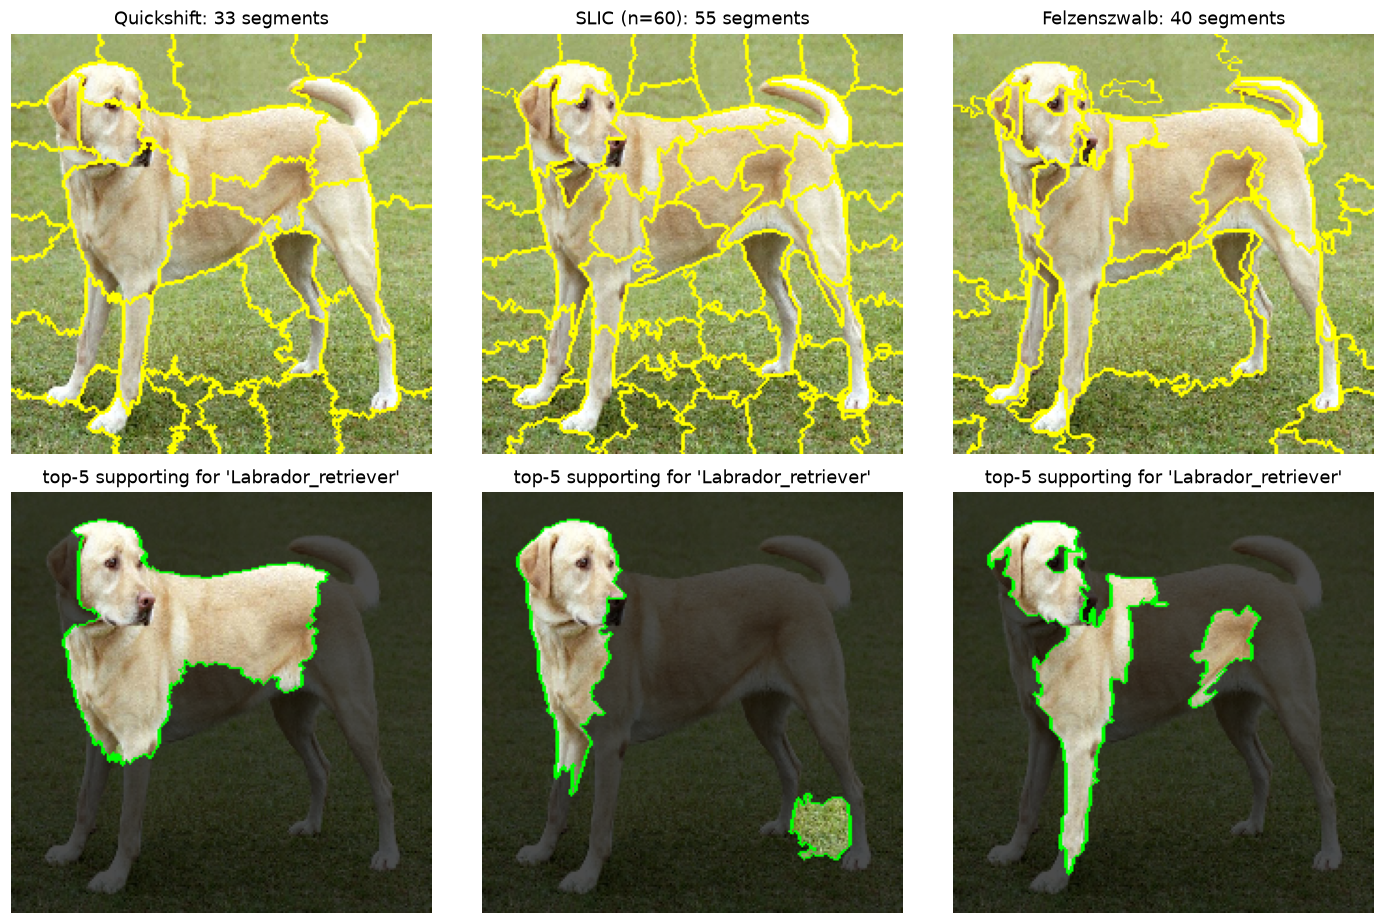

,segmenter,superpixels,local R²,seconds
0,Quickshift,33,0.479,11.548
1,SLIC (n=60),55,0.420,9.761
2,Felzenszwalb,40,0.382,9.497


In [34]:
segmenters = {
    "Quickshift": quickshift,
    "SLIC (n=60)": SegmentationAlgorithm("slic", n_segments=60, compactness=10, sigma=1, start_label=0),
    "Felzenszwalb": SegmentationAlgorithm("felzenszwalb", scale=100, sigma=0.8, min_size=150),
}
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
seg_rows = []
for col, (name, fn) in enumerate(segmenters.items()):
    segs = fn(img)
    t = time.time()
    e = LimeImageExplainer(random_state=SEED).explain_instance(
        img, classify, labels=[pred_id], top_labels=None, hide_color=0, num_samples=500,
        batch_size=50, segmentation_fn=fn, random_seed=SEED)
    _, m = e.get_image_and_mask(pred_id, positive_only=True, num_features=5, hide_rest=False)
    seg_rows.append({"segmenter": name, "superpixels": segs.max() + 1, "local R²": e.score,
                     "seconds": time.time() - t})
    axes[0, col].imshow(mark_boundaries(img, segs, color=(1, 1, 0))); axes[0, col].set_title(f"{name}: {segs.max() + 1} segments")
    axes[1, col].imshow(mark_boundaries(img * 0.3 + 0.7 * img * m[..., None], m, color=(0, 1, 0)))
    axes[1, col].set_title(f"top-5 supporting for '{pred_name}'")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame(seg_rows).round(3))

---
# Summary

| | Q1 Tabular | Q2 Text | Q3 Image |
|---|---|---|---|
| Interpretable features | discretized feature rules | presence of each word | presence of each superpixel |
| Perturbation | resample features from training distribution | delete random words | black out random superpixels |
| Main finding | malignant call driven by *worst* size/concavity features | sentiment carried by a handful of strongly polar words; removing two of them changes P(positive) a lot | the dog's face/head regions support the class; masking them drops the probability far more than random masks |
| ★ Faithfulness check | deletion test beats random features | LIME ranking correlates with leave-one-word-out | deletion curve beats random order |

**Takeaways.** LIME is model-agnostic and gives readable, local explanations. However, it is *random* (check stability), its perturbations can be unrealistic (correlated features, black patches), and the explanation depends on choices you make (kernel width, number of samples, discretization, segmentation). Always pair it with a sanity check such as a deletion test.